# Fase 2: Comprensión de los Datos / Data Understanding
La fase de comprensión de datos comienza con una recopilación inicial de datos y continúacon actividades para familiarizarse con los datos, identificar problemas de calidad de losdatos, descubrir los primeros conocimientos sobre los datos o detectar subconjuntos interesantes para formular hipótesis sobre información oculta.
* Establecé una metodología de adquisición de los datos para el negocio.
* Contemplá en la adquisición de datos una alternativa donde debas construir el setde datos.
* Identificá los distintos problemas o desafíos con los datos (datos faltantes, ruidos,etc) que puedan afectar a su calidad.
* Enumerá las distintas fases, tareas generales, tareas específicas e instancias del proceso que incluirás como estrategia para aplicar la metodología

## 2.1 Fuente y licencia de uso
Como fuente principal de datos se utiliza el conjunto de datos públicos correspondiente al Adjunto IV, de la Secretaría de Energía de la Nación, el cual registra las operaciones de fractura hidráulica llevadas a cabo en pozos de hidrocarburos no convencionales en Argentina.

El conjunto de datos cuenta con una ficha descriptiva en el portal oficial cuya última edición data del 5 de septiembre de 2024; no obstante, el recurso en formato CSV se mantiene con actualización periódica automatizada (declarada con frecuencia diaria), reflejando las declaraciones juradas y operaciones más recientes cargadas por las operadoras.

Se distribuye bajo la licencia internacional Creative Commons Attribution 4.0 (CC BY 4.0), que permite la descarga, reutilización, adaptación y distribución libre de la información para fines académicos y de investigación; con el único requisito de brindar el reconocimiento y citación adecuada a la fuente oficial.


## 2.2. Comprensión de los datos (ADAPTENMENTEN)

En esta fase se realiza la comprensión del conjunto de datos que será utilizado para el análisis. El dataset utilizado corresponde a las variedades de arroz Cammeo y Osmancik, y contiene variables numéricas que describen características geométricas de los granos de arroz obtenidas mediante procesamiento de imágenes.

Cada registro del dataset representa un grano de arroz y cada columna representa una característica medida del mismo. Entre las variables presentes en el dataset se encuentran:

* Área
* Perímetro
* Longitud del eje mayor
* Longitud del eje menor
* Excentricidad
* Convex Area
* Extent
* Solidez
* Roundness
* Aspect Ratio
* Clase (Cammeo u Osmancik)

La variable Clase corresponde a la variable objetivo, ya que es la variable que se desea predecir mediante el modelo de clasificación.

El objetivo de esta fase es entender la estructura de los datos, identificar el tipo de variables, detectar valores faltantes, analizar la distribución de las variables y estudiar la relación entre ellas.

## 2.3. Carga del dataset

In [ ]:
# @title 2.3.1 Imports
import pandas as pd
import requests
import urllib3
import seaborn as sns

from comun import RUTA_DATOS


In [ ]:
# @title 2.3.2. Descarga de archivo
# Silenciar advertencias de certificados no verificados
def descargar_dataset():
	urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

	url = "https://datos.energia.gob.ar/dataset/71fa2e84-0316-4a1b-af68-7f35e41f58d7/resource/2280ad92-6ed3-403e-a095-50139863ab0d/download/datos-de-fractura-de-pozos-de-hidrocarburos-adjunto-iv-actualizacin-diaria.csv"
	headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"}

	# Realizar la descarga en bloques (stream) para evitar sobrecargar memoria
	with requests.get(url, headers=headers, verify=False, stream=True, timeout=60) as r:
		r.raise_for_status()
		with open(RUTA_DATOS, "wb") as f:
			for chunk in r.iter_content(chunk_size=8192):
				f.write(chunk)

	print("Descarga completada con éxito.")


descargar_dataset()

Descarga completada con éxito.


In [ ]:
# @title 2.3.3. Carga de datos

# Cargar el archivo CSV descargado en un DataFrame de pandas
df_datos_energia = pd.read_csv(RUTA_DATOS)

# Visualizar las primeras filas del DataFrame
df_datos_energia.head()

,id_base_fractura_adjiv,idpozo,sigla,cuenca,areapermisoconcesion,yacimiento,formacion_productiva,tipo_reservorio,subtipo_reservorio,longitud_rama_horizontal_m,...,fecha_data,anio_if,mes_if,anio_ff,mes_ff,anio_carga,mes_carga,empresa_informante,mes,anio
0,30,159910,APS.Nq.ADC.xp-1033,NEUQUINA,AGUA DEL CAJON,AGUA DEL CAJON,los molles,NO CONVENCIONAL,SHALE,0.0,...,2019-06-14 17:13:03.68279,2019,4,2019,4,2019,6,CAPEX S.A.,4,2019
1,31,159910,APS.Nq.ADC.xp-1033,NEUQUINA,AGUA DEL CAJON,AGUA DEL CAJON,los molles,NO CONVENCIONAL,SHALE,0.0,...,2019-06-14 17:14:19.179874,2018,11,2018,11,2019,6,CAPEX S.A.,11,2018
2,37,159219,YPF.Nq.AdlA-1001(h),NEUQUINA,AGUADA DE LA ARENA,AGUADA DE LA ARENA,vaca muerta,NO CONVENCIONAL,SHALE,1437.3,...,2019-06-27 13:46:21.14935,2017,11,2017,12,2019,6,YPF S.A.,11,2017
3,38,159220,YPF.Nq.AdlA-1002(h),NEUQUINA,AGUADA DE LA ARENA,AGUADA DE LA ARENA,vaca muerta,NO CONVENCIONAL,SHALE,1518.3,...,2019-06-27 13:46:21.14935,2017,11,2017,12,2019,6,YPF S.A.,11,2017
4,39,159221,YPF.Nq.AdlA-1003(h),NEUQUINA,AGUADA DE LA ARENA,AGUADA DE LA ARENA,vaca muerta,NO CONVENCIONAL,SHALE,1482.3,...,2019-06-27 13:46:21.14935,2017,11,2017,12,2019,6,YPF S.A.,11,2017


## 2.4. Análisis exploratorio de los datos (EDA)
El Análisis Exploratorio de Datos (EDA) permite obtener una primera comprensión del comportamiento de las variables y su relación con la variable objetivo. Esta etapa es fundamental antes de construir modelos de machine learning, ya que permite detectar problemas en los datos y entender qué variables pueden tener mayor poder explicativo.

#### 2.4.1. Análisis de la estructura del dataset

En primer lugar, se analiza:

* Cantidad de filas (observaciones)
* Cantidad de columnas (variables)
* Tipos de datos de cada variable
* Identificación de la variable objetivo
* Identificación de variables numéricas y categóricas

Este análisis permite entender la dimensionalidad del problema y el tipo de modelo que se deberá utilizar posteriormente.

In [ ]:
# @title Cantidad de filas y columnas
num_filas, num_columnas = df_datos_energia.shape
print(f"El Dataset tiene {num_filas} filas y {num_columnas} columnas.")

El Dataset tiene 4983 filas y 30 columnas.


In [ ]:
# @title Tipos de datos por columna
df_datos_energia.info()

<class 'pandas.DataFrame'>
RangeIndex: 4983 entries, 0 to 4982
Data columns (total 30 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   id_base_fractura_adjiv        4983 non-null   int64  
 1   idpozo                        4983 non-null   int64  
 2   sigla                         4983 non-null   str    
 3   cuenca                        4983 non-null   str    
 4   areapermisoconcesion          4983 non-null   str    
 5   yacimiento                    4983 non-null   str    
 6   formacion_productiva          4983 non-null   str    
 7   tipo_reservorio               4948 non-null   str    
 8   subtipo_reservorio            4010 non-null   str    
 9   longitud_rama_horizontal_m    4983 non-null   float64
 10  cantidad_fracturas            4983 non-null   int64  
 11  tipo_terminacion              4983 non-null   str    
 12  arena_bombeada_nacional_tn    4983 non-null   float64
 13  arena_bombeada

In [6]:
# @title Análisis de duplicados y cardinalidad de pozos
# Duplicados exactos en todo el DataFrame
print("Filas duplicadas exactas:", df_datos_energia.duplicated().sum())

# Duplicados en la clave primaria
print("IDs de fractura duplicados:", df_datos_energia.duplicated(subset=["id_base_fractura_adjiv"]).sum())

# Cuántas fracturas tiene cada pozo (cardinalidad de pozos)
print("Pozos únicos:", df_datos_energia["idpozo"].nunique())

Filas duplicadas exactas: 0
IDs de fractura duplicados: 0
Pozos únicos: 4739


In [7]:
# @title Análisis de columnas con un único valor
# Ver columnas que tienen un único valor en todas sus filas
cols_univalor = [col for col in df_datos_energia.columns if df_datos_energia[col].nunique() == 1]
print("Columnas con un único valor (que no son útiles para modelar):", cols_univalor)

# Chequear específicamente co2_inyectado_m3 (suele ser 0 en la mayoría)
print("Distribución de CO2 inyectado:")
print(df_datos_energia["co2_inyectado_m3"].value_counts(dropna=False).head())

Columnas con un único valor (que no son útiles para modelar): []
Distribución de CO2 inyectado:
co2_inyectado_m3
0.0     4824
49.0       4
51.0       3
59.0       3
48.0       3
Name: count, dtype: int64


No se identificaron columnas con varianza estrictamente nula, por lo que ninguna variable queda descartada de forma automática por invariabilidad total.

El 96.8% de los registros (4.824 de 4.983 filas) presenta un valor de $0.0\text{ m}^3$, evidenciando que el uso de dióxido de carbono es una práctica marginal en las operaciones registradas.

**Debido a su comportamiento cuasi-constante, mantener esta variable en su escala continua introduce ruido sin aportar poder predictivo. Evaluar su eliminación para reducir dimensionalidad o transformarla en una variable dummy si el aspecto operativo resulta crítico para el objetivo**

In [14]:
# @Cobertura temporal
# Convertir columnas a formato temporal

df_datos_energia["f_inicio"] = pd.to_datetime(df_datos_energia["fecha_inicio_fractura"], errors="raise")
df_datos_energia["f_fin"] = pd.to_datetime(df_datos_energia["fecha_fin_fractura"], errors="raise")
df_datos_energia["f_carga"] = pd.to_datetime(df_datos_energia["fecha_data"], errors="raise")

# 1. Rango global de operaciones
print(f"Inicio más antiguo: {df_datos_energia['f_inicio'].min().date()}")
print(f"Fin más reciente:   {df_datos_energia['f_fin'].max().date()}")

# 2. Duración de la operación (días de bombeo/estimulación)
df_datos_energia["duracion_dias"] = (df_datos_energia["f_inicio"] - df_datos_energia["f_inicio"]).dt.total_seconds() / (24 * 3600)

print("\n--- Duración de Fractura (Días) ---")
print(df_datos_energia["duracion_dias"].describe(percentiles=[0.05, 0.5, 0.95]))

# 3. Latencia administrativa (cuánto tardan en cargar el dato al sistema desde que finaliza)
df_datos_energia["latencia_dias"] = (df_datos_energia["f_carga"] - df_datos_energia["f_inicio"]).dt.total_seconds() / (24 * 3600)
print(f"\nMediana de tiempo de reporte administrativo: {df_datos_energia['latencia_dias'].median():.1f} días")

# 4. Volumen de operaciones por año
print("\n--- Operaciones por Año de Inicio ---")
print(df_datos_energia["f_inicio"].dt.year.value_counts().sort_index())

Inicio más antiguo: 2006-05-19
Fin más reciente:   2026-08-02

--- Duración de Fractura (Días) ---
count    4983.0
mean        0.0
std         0.0
min         0.0
5%          0.0
50%         0.0
95%         0.0
max         0.0
Name: duracion_dias, dtype: float64

Mediana de tiempo de reporte administrativo: 415.4 días

--- Operaciones por Año de Inicio ---
f_inicio
2006      1
2009      5
2010    128
2011    160
2012    170
2013    215
2014    325
2015    344
2016    266
2017    293
2018    349
2019    320
2020    118
2021    354
2022    429
2023    420
2024    383
2025    463
2026    240
Name: count, dtype: int64


### 2.4.2 Análisis estadístico descriptivo

Se realiza un análisis estadístico descriptivo de las variables numéricas, calculando:

* Media
* Mediana
* Desvío estándar
* Valor mínimo
* Valor máximo
* Cuartiles (Q1, Q2, Q3)

Este análisis permite entender la dispersión de los datos, detectar posibles outliers y analizar si las variables presentan comportamientos muy diferentes entre sí.

In [ ]:
# @title Codiguito descriptivo
df_datos_energia.describe()

### 2.4.3 Análisis de valores faltantes

En esta etapa se verifica la existencia de valores faltantes en el dataset. La presencia de valores nulos puede afectar el rendimiento de los modelos de machine learning, por lo que es importante detectarlos y definir una estrategia para tratarlos (eliminación de registros, imputación, etc.).

En caso de que el dataset no presente valores faltantes, esto representa una ventaja, ya que no será necesario realizar procesos de imputación.

In [ ]:
# @title Ver columnas con algun faltante
df_datos_energia.isnull().sum()

### 2.4.4 Análisis de la distribución de las variables

Se analizan las distribuciones de las variables numéricas mediante histogramas y diagramas de caja (boxplots). Este análisis permite:

* Detectar outliers.
* Analizar la dispersión de los datos.
* Identificar si las variables presentan distribución normal o sesgada.
* Comparar la distribución de las variables entre las clases Cammeo y Osmancik.

Este punto es muy importante, ya que si las variables presentan diferencias significativas entre las clases, entonces serán buenas variables predictoras para el modelo de clasificación.

<Axes: title={'center': 'agua_inyectada_m3'}, xlabel='cuenca'>

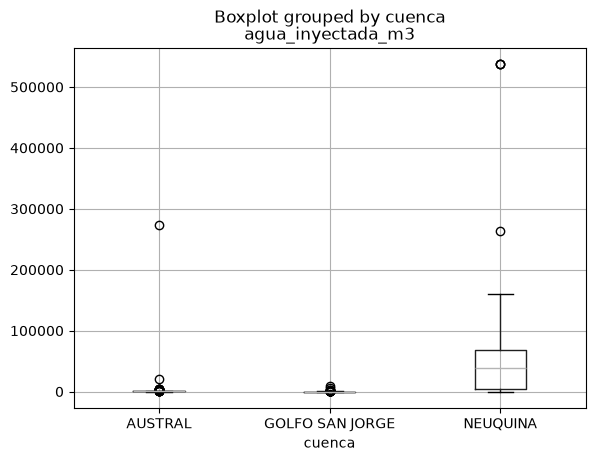

In [ ]:
# @title AVERIGUAR LOS OUTLIERS!
df_datos_energia.boxplot(column="agua_inyectada_m3", by="cuenca", grid=True)

### 2.4.5 Análisis de correlación entre variables

Se construye una matriz de correlación para analizar la relación entre las variables numéricas. La correlación permite identificar:

* Variables altamente correlacionadas entre sí.
* Posibles problemas de multicolinealidad.
* Variables que pueden aportar información similar al modelo.

Si existen variables muy correlacionadas entre sí, podría ser conveniente eliminar alguna de ellas en etapas posteriores para evitar redundancia en el modelo.

In [ ]:
# @title Diagramas de dispersion y calculos de correlación

# un mapa de calor maybe?
# sns.corr

# df_datos_energia.
# ACÁ HACER UNA MATRIZ DE correlación MUCHOS CONTRA MUCHOS


### 2.4.6. Relación entre variables y la variable objetivo

En esta etapa se analiza cómo se comportan las variables numéricas según la clase (Cammeo u Osmancik). Esto puede realizarse mediante:

* Boxplots por clase.
* Gráficos de dispersión.
* Comparación de medias por clase.
* Histogramas separados por clase.

Este análisis permite identificar qué variables diferencian mejor una variedad de arroz de la otra, lo cual es fundamental para la construcción del modelo de clasificación.

In [ ]:
# @title Merca Merca merca

# Y ACA HACER CORRELACIOENS O GROUPBIES ESPECIFICOS ENTRE agua_inyectada_m3 CONTRA categoricas o contra otras variables continuas




## 3. Conclusiones de la fase de exploración

El archivo analizado contiene **4.910 registros y 30 variables**. La huella SHA-256 permite reconocer esta versión exacta del CSV, cuya fecha máxima de carga es el **29/09/2026**. Después de aplicar todos los criterios quedan **2.626 registros de 2.592 pozos**. La diferencia entre registros y pozos confirma que algunos pozos tienen más de una intervención; por eso `idpozo` se conserva como control y no como variable predictora.

Los filtros son secuenciales: `excluidos_en_paso` se interpreta respecto del paso anterior, no del archivo completo. Primero se retiraron 803 registros de otras cuencas y luego 376 correspondientes a reservorios convencionales dentro de la cuenca Neuquina. La mayor reducción posterior proviene de **1.071 registros sin una rama horizontal positiva**, coherente con el alcance limitado a pozos horizontales. También se excluyeron dos registros sin agua positiva y 32 con fecha de finalización anterior a la fecha de inicio.

El conjunto final representa aproximadamente el **53,5 %** del archivo original. Esta reducción no implica por sí sola mala calidad: una parte importante queda afuera por definición del alcance. En cambio, las fechas invertidas sí constituyen un problema de consistencia. Los resultados sólo describen el subconjunto retenido y no deben generalizarse a pozos convencionales, verticales u otras cuencas.